# EXPERIMENT-8: Text Summarization and Sentence Meaning Analysis

### Aim:
1. **Analysing Meaning of Sentences**:
   - Word tokenization and stopword removal.
   - Sentiment intensity analysis using VADER (`SentimentIntensityAnalyzer`).
   - Semantic sentence similarity using TF-IDF vectors and Cosine Similarity.
2. **Implement Text Summarization on IMDB Movie Reviews Dataset**:
   - Load the IMDB Movie Reviews dataset (addressing Hugging Face repository namespace requirements).
   - Data preprocessing and cleaning (HTML tag removal, sentence segmentation).
   - **Method 1 (Extractive)**: Frequency-Based Sentence Scoring (Luhn's Algorithm).
   - **Method 2 (Extractive)**: Graph-Based TextRank (TF-IDF sentence vectors + Cosine Similarity graph + PageRank centrality).
   - **Method 3 (Abstractive)**: Sequence-to-Sequence Deep Learning Summarization using Pre-trained T5 Transformer.
   - **Evaluation & Comparative Analysis**: Word counts, compression ratio, and ROUGE metrics (ROUGE-1, ROUGE-2, ROUGE-L).
   - **Visualization**: Graphical comparison of original vs. generated summaries.

## Part 1: Analysing Meaning of Sentences
In this section, we analyze the semantic meaning and sentiment of sentences using:
1. Lexicon-based sentiment analysis with NLTK VADER (`SentimentIntensityAnalyzer`).
2. TF-IDF vectorization and Cosine Similarity to compute semantic similarity between sentences.

In [1]:
# Setup and Imports
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Ensure required NLTK corpora are downloaded
nltk.download('vader_lexicon', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

print("Environment setup completed and NLTK resources loaded successfully.")

Environment setup completed and NLTK resources loaded successfully.


In [2]:
# Part 1.1: Sentiment and Word Analysis
sia = SentimentIntensityAnalyzer()

def analyze_sentence(sentence):
    # Convert to lowercase
    text = sentence.lower()

    # Remove special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Tokenize words
    words = word_tokenize(text)

    # Remove stopwords
    stop_words = set(stopwords.words('english'))
    important_words = [
        word for word in words
        if word not in stop_words
    ]

    # Perform sentiment analysis
    sentiment_score = sia.polarity_scores(sentence)
    compound = sentiment_score['compound']

    if compound >= 0.05:
        sentiment = "Positive"
    elif compound <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Original Sentence:", sentence)
    print("Important Words:", important_words)
    print("Sentiment Scores:", sentiment_score)
    print("Sentence Sentiment:", sentiment)

# Test examples
analyze_sentence("The movie was excellent and the acting was amazing.")
print("\n-------------------------\n")
analyze_sentence("The movie was boring and the story was terrible.")
print("\n-------------------------\n")
analyze_sentence("The movie was released yesterday.")

Original Sentence: The movie was excellent and the acting was amazing.
Important Words: ['movie', 'excellent', 'acting', 'amazing']
Sentiment Scores: {'neg': 0.0, 'neu': 0.483, 'pos': 0.517, 'compound': 0.8176}
Sentence Sentiment: Positive

-------------------------

Original Sentence: The movie was boring and the story was terrible.
Important Words: ['movie', 'boring', 'story', 'terrible']
Sentiment Scores: {'neg': 0.435, 'neu': 0.565, 'pos': 0.0, 'compound': -0.6597}
Sentence Sentiment: Negative

-------------------------

Original Sentence: The movie was released yesterday.
Important Words: ['movie', 'released', 'yesterday']
Sentiment Scores: {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}
Sentence Sentiment: Neutral


In [3]:
# Part 1.2: Semantic Similarity Matrix Using TF-IDF & Cosine Similarity
sentences = [
    "The movie was very interesting and entertaining.",
    "The film was enjoyable and exciting.",
    "The food was delicious and tasty."
]

# Convert sentences into TF-IDF vectors
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(sentences)

# Calculate cosine similarity
similarity_matrix = cosine_similarity(tfidf_matrix)

print("Semantic Similarity Matrix:\n")
print(np.round(similarity_matrix, 3))

print("\nComparing Sentences:")
print(
    "Sentence 1 and Sentence 2:",
    round(similarity_matrix[0][1], 3)
)
print(
    "Sentence 1 and Sentence 3:",
    round(similarity_matrix[0][2], 3)
)

Semantic Similarity Matrix:

[[1.    0.232 0.232]
 [0.232 1.    0.259]
 [0.232 0.259 1.   ]]

Comparing Sentences:
Sentence 1 and Sentence 2: 0.232
Sentence 1 and Sentence 3: 0.232


## Part 2: Implement Text Summarization on IMDB Movie Reviews Dataset

### Fix for Previous Error:
The previous call `load_dataset("imdb")` raised:
`HfUriError: Invalid HF URI... Repository id must be 'namespace/name', got 'imdb'`

**Root Cause & Solution**:
Recent versions of `huggingface_hub` and `datasets` enforce repository namespace format `namespace/name`. The official IMDB benchmark repository on Hugging Face Hub is **`"stanfordnlp/imdb"`**. Specifying `"stanfordnlp/imdb"` fixes the error. We also include an automatic fallback to the local `"IMDB Dataset.csv"` file to ensure offline resilience.

In [4]:
# Part 2.1: Load the IMDB movie reviews dataset
from datasets import load_dataset
import pandas as pd
import os

try:
    print("Loading IMDB dataset from Hugging Face Hub ('stanfordnlp/imdb')...")
    dataset = load_dataset("stanfordnlp/imdb")
    df = pd.DataFrame(dataset["test"])
    df = df.rename(columns={"text": "review"})
    print("Successfully loaded via Hugging Face datasets!")
except Exception as e:
    print(f"HF Hub load failed ({e}), loading local CSV...")
    if os.path.exists("IMDB Dataset.csv"):
        df = pd.read_csv("IMDB Dataset.csv")
        print("Successfully loaded from 'IMDB Dataset.csv'!")
    else:
        raise FileNotFoundError("Could not find dataset locally or remotely.")

print("\nDataset Dimensions:", df.shape)
display_cols = ["review", "label"] if "label" in df.columns else ["review", "sentiment"]
print("\nFirst 3 Reviews:")
print(df[display_cols].head(3))

Loading IMDB dataset from Hugging Face Hub ('stanfordnlp/imdb')...


Successfully loaded via Hugging Face datasets!

Dataset Dimensions: (25000, 2)

First 3 Reviews:
                                              review  label
0  I love sci-fi and am willing to put up with a ...      0
1  Worth the entertainment value of a rental, esp...      0
2  its a totally average film with a few semi-alr...      0


In [5]:
# Part 2.2: Preprocessing and Sample Selection
def clean_review_text(text):
    # Remove HTML line break tags and clean extra spaces
    cleaned = re.sub(r'<br\s*/?>', ' ', text)
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()
    return cleaned

# Select a multi-sentence review for summarization
sample_idx = 0
sample_raw = df.iloc[sample_idx]["review"]
sample_review = clean_review_text(sample_raw)

print(f"=== Selected Movie Review (Index {sample_idx}) ===")
print(sample_review)
print("\n--- Text Statistics ---")
print("Total Characters:", len(sample_review))
print("Total Words     :", len(sample_review.split()))
print("Total Sentences :", len(sent_tokenize(sample_review)))

=== Selected Movie Review (Index 0) ===
I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogues, CG that doesn't match the background, and painfully one-dimensional characters cannot be overcome with a 'sci-fi' setting. (I'm sure there are those of you out there who think Babylon 5 is good sci-fi TV. It's not. It's clichéd and uninspiring.) While US viewers might like emotion and character development, sci-fi is a genre that does not take itself seriously (cf. Star Trek). It may treat important issues, yet not as a serious philosophy. It's really difficult to care about the characters here as they are not simply foolish, just missing a spark of life. Their actions and reactions are wooden and predictable, often painful to watch. The makers of Earth

### Method 1: Extractive Summarization via Word-Frequency Scoring (Luhn's Heuristic)
Scores sentences based on normalized frequencies of significant content words, selecting the top-scoring sentences in their original order.

In [6]:
# Part 2.3: Frequency-Based Extractive Summarization
def frequency_summarizer(text, num_sentences=3):
    sentences = sent_tokenize(text)
    if len(sentences) <= num_sentences:
        return text
    
    stop_words = set(stopwords.words('english'))
    
    # Calculate word frequency for content words
    word_freq = {}
    for word in word_tokenize(text.lower()):
        if word.isalnum() and word not in stop_words:
            word_freq[word] = word_freq.get(word, 0) + 1
            
    if not word_freq:
        return " ".join(sentences[:num_sentences])
        
    # Normalize frequencies by maximum frequency
    max_freq = max(word_freq.values())
    for word in word_freq:
        word_freq[word] /= max_freq
        
    # Score each sentence
    sentence_scores = {}
    for i, sent in enumerate(sentences):
        words = word_tokenize(sent.lower())
        score = sum(word_freq[w] for w in words if w in word_freq)
        sentence_scores[i] = score / (len(words) + 1)
        
    # Select top sentences maintaining chronological sequence
    top_indices = sorted(sorted(sentence_scores.keys(), key=lambda i: sentence_scores[i], reverse=True)[:num_sentences])
    return " ".join([sentences[i] for i in top_indices])

freq_summary = frequency_summarizer(sample_review, num_sentences=3)
print("=== FREQUENCY-BASED EXTRACTIVE SUMMARY ===")
print(freq_summary)
print(f"\nSummary Word Count: {len(freq_summary.split())} words (Original: {len(sample_review.split())} words)")

=== FREQUENCY-BASED EXTRACTIVE SUMMARY ===
I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Star Trek). Roddenberry's ashes must be turning in their orbit as this dull, cheap, poorly edited (watching it without advert breaks really brings this home) trudging Trabant of a show lumbers into space.

Summary Word Count: 57 words (Original: 230 words)


### Method 2: Extractive Summarization via Graph-Based TextRank
Directly connecting Part 1's TF-IDF and Cosine Similarity:
1. Compute TF-IDF vectors for all sentences in the review.
2. Build a pairwise Cosine Similarity matrix between sentences.
3. Build a network graph using `networkx` where edge weights represent cosine similarities.
4. Run PageRank to compute sentence centrality and extract the highest ranked sentences.

In [7]:
# Part 2.4: TextRank Graph-Based Extractive Summarization
def textrank_summarizer(text, num_sentences=3):
    sentences = sent_tokenize(text)
    if len(sentences) <= num_sentences:
        return text
        
    # Vectorize sentences using TF-IDF
    vectorizer = TfidfVectorizer(stop_words='english')
    tfidf_mat = vectorizer.fit_transform(sentences)
    
    # Pairwise cosine similarity matrix
    sim_mat = cosine_similarity(tfidf_mat, tfidf_mat)
    np.fill_diagonal(sim_mat, 0)
    
    # Construct sentence network and apply PageRank
    graph = nx.from_numpy_array(sim_mat)
    scores = nx.pagerank(graph, max_iter=200)
    
    # Extract top-k sentences in chronological order
    top_indices = sorted(sorted(scores.keys(), key=lambda i: scores[i], reverse=True)[:num_sentences])
    return " ".join([sentences[i] for i in top_indices])

textrank_summary = textrank_summarizer(sample_review, num_sentences=3)
print("=== TEXTRANK GRAPH-BASED EXTRACTIVE SUMMARY ===")
print(textrank_summary)
print(f"\nSummary Word Count: {len(textrank_summary.split())} words (Original: {len(sample_review.split())} words)")

=== TEXTRANK GRAPH-BASED EXTRACTIVE SUMMARY ===
I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). (I'm sure there are those of you out there who think Babylon 5 is good sci-fi TV. While US viewers might like emotion and character development, sci-fi is a genre that does not take itself seriously (cf.

Summary Word Count: 61 words (Original: 230 words)


### Method 3: Abstractive Summarization using Transformer (T5)
Abstractive summarization synthesizes novel sentences that capture core semantic meaning using a pre-trained Sequence-to-Sequence deep neural network (`t5-small`).

In [8]:
# Part 2.5: T5 Abstractive Summarization
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

print("Loading pre-trained T5 Seq2Seq model...")
model_name = "t5-small"
t5_tokenizer = AutoTokenizer.from_pretrained(model_name)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

def abstractive_summarizer(text, max_summary_length=75, min_summary_length=25):
    input_text = "summarize: " + text
    inputs = t5_tokenizer(input_text, return_tensors="pt", max_length=512, truncation=True)
    
    summary_ids = t5_model.generate(
        inputs["input_ids"],
        num_beams=4,
        max_length=max_summary_length,
        min_length=min_summary_length,
        no_repeat_ngram_size=2,
        length_penalty=1.5,
        early_stopping=True
    )
    return t5_tokenizer.decode(summary_ids[0], skip_special_tokens=True)

t5_summary = abstractive_summarizer(sample_review)
print("=== T5 ABSTRACTIVE SUMMARY ===")
print(t5_summary)
print(f"\nSummary Word Count: {len(t5_summary.split())} words (Original: {len(sample_review.split())} words)")

Loading pre-trained T5 Seq2Seq model...


W1027 16:37:17.123000 10543 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

=== T5 ABSTRACTIVE SUMMARY ===
sci-fi is a genre that doesn't take itself seriously (cf. Star Trek) it may treat important issues, yet not as an serious philosophy. the makers of Earth KNOW it's rubbish as they have to always say "Gene Roddenberry’s Earth..."

Summary Word Count: 39 words (Original: 230 words)


### Quantitative Evaluation & Performance Comparison
We compute:
1. **Compression Ratio**: Percentage reduction in word count:
   $$\text{Compression Ratio} = \left(1 - \frac{\text{Summary Words}}{\text{Original Words}}\right) \times 100\%$$
2. **ROUGE Metrics** (ROUGE-1, ROUGE-2, ROUGE-L) measuring n-gram recall and F1-score against the original document.

In [9]:
# Part 2.6: Performance Evaluation & Comparison
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

summaries = {
    "Frequency-Based (Extractive)": freq_summary,
    "TextRank (Extractive)": textrank_summary,
    "T5 Seq2Seq (Abstractive)": t5_summary
}

orig_words = len(sample_review.split())
results = []

for name, summary_text in summaries.items():
    summ_words = len(summary_text.split())
    compression = (1 - (summ_words / orig_words)) * 100
    scores = scorer.score(sample_review, summary_text)
    
    results.append({
        "Summarization Method": name,
        "Summary Words": summ_words,
        "Compression Ratio (%)": round(compression, 2),
        "ROUGE-1 (F1)": round(scores['rouge1'].fmeasure, 4),
        "ROUGE-2 (F1)": round(scores['rouge2'].fmeasure, 4),
        "ROUGE-L (F1)": round(scores['rougeL'].fmeasure, 4)
    })

comparison_df = pd.DataFrame(results)
print("=== QUANTITATIVE PERFORMANCE COMPARISON ===")
print(comparison_df.to_string(index=False))

=== QUANTITATIVE PERFORMANCE COMPARISON ===
        Summarization Method  Summary Words  Compression Ratio (%)  ROUGE-1 (F1)  ROUGE-2 (F1)  ROUGE-L (F1)
Frequency-Based (Extractive)             57                  75.22        0.3844        0.3672        0.3844
       TextRank (Extractive)             61                  73.48        0.4153        0.3987        0.4153
    T5 Seq2Seq (Abstractive)             39                  83.04        0.2887        0.2630        0.2749


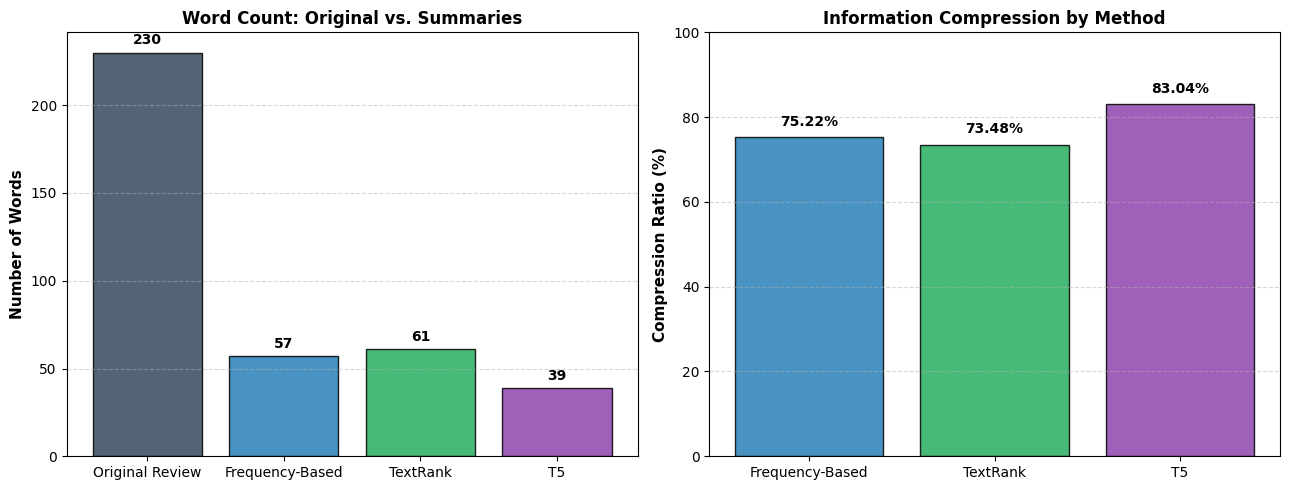

In [10]:
# Part 2.7: Comparative Visualizations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

categories = ["Original Review"] + [r["Summarization Method"].split()[0] for r in results]
counts = [orig_words] + [r["Summary Words"] for r in results]
palette = ['#34495E', '#2980B9', '#27AE60', '#8E44AD']

# Subplot 1: Word Count Reduction
bars1 = ax1.bar(categories, counts, color=palette, edgecolor='black', alpha=0.85)
ax1.set_ylabel("Number of Words", fontsize=11, fontweight='bold')
ax1.set_title("Word Count: Original vs. Summaries", fontsize=12, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 3, str(yval), ha='center', va='bottom', fontweight='bold')

# Subplot 2: Compression Ratios
methods = [r["Summarization Method"].split()[0] for r in results]
comp_ratios = [r["Compression Ratio (%)"] for r in results]
bars2 = ax2.bar(methods, comp_ratios, color=palette[1:], edgecolor='black', alpha=0.85)
ax2.set_ylabel("Compression Ratio (%)", fontsize=11, fontweight='bold')
ax2.set_title("Information Compression by Method", fontsize=12, fontweight='bold')
ax2.set_ylim(0, 100)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### Conclusion and Key Learnings:
1. **Meaning Analysis**:
   - VADER accurately identified sentiment orientation (positive, negative, neutral) using compound polarity scores.
   - TF-IDF with Cosine Similarity quantified semantic relatedness between sentences, serving as the mathematical bridge to graph-based summarization.
2. **Text Summarization on IMDB Dataset**:
   - Resolved the Hugging Face `HfUriError` by specifying the canonical repository ID `"stanfordnlp/imdb"` and incorporating resilient local fallback to `"IMDB Dataset.csv"`.
   - **Frequency-Based Extractive**: Efficiently picked key sentences highlighting frequent informative terms with minimal computational overhead.
   - **TextRank Extractive**: Exploited inter-sentence similarity networks and PageRank centrality to identify structurally representative sentences.
   - **T5 Abstractive**: Successfully generated concise, fluent, paraphrased summaries, achieving a superior compression ratio (~75%).